In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
print("libraries imported successfully.")

libraries imported successfully.


In [3]:
matches=pd.read_csv("../data/processed/epl_matches_stage1.csv")
matches["Date"]=pd.to_datetime(
    matches["Date"],
    errors="coerce",
    dayfirst=True
)
print(matches.tail())
matches.shape

      Unnamed: 0  MatchWeek       Date      HomeTeam FullTimeScore  \
4175        4175         38 2021-05-23      West Ham           3–0   
4176        4176         38 2021-05-23  Leeds United           3–1   
4177        4177         38 2021-05-23       Arsenal           2–0   
4178        4178         38 2021-05-23     Liverpool           2–0   
4179        4179         38 2021-05-23        Fulham           0–2   

            AwayTeam  Source_File  HomeGoals  AwayGoals MatchResult  
4175     Southampton  epl_2020_21          3          0          HW  
4176       West Brom  epl_2020_21          3          1          HW  
4177        Brighton  epl_2020_21          2          0          HW  
4178  Crystal Palace  epl_2020_21          2          0          HW  
4179   Newcastle Utd  epl_2020_21          0          2          AW  


C:\Users\anamo\AppData\Local\Temp\ipykernel_4680\2031920260.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  matches["Date"]=pd.to_datetime(


(4180, 10)

In [ ]:
#Investigate data quality
missing_report=pd.DataFrame({
    "Missing_Count":matches.isnull().sum(),
    "Missing_Percentage": (matches.isnull().mean()*100).round(2)
})
print(missing_report)
#Duplicate Records
duplicate_count=matches.duplicated(subset=["Date", "HomeTeam", "AwayTeam", "FullTimeScore"]).sum()
print("Potential duplicate matches: ", duplicate_count)
#Invalid Scores
invalid_scores=matches[
    matches["HomeGoals"].isna()|matches["AwayGoals"].isna()
]
print("Invalid score records: ", len(invalid_scores))

               Missing_Count  Missing_Percentage
Unnamed: 0                 0                0.00
MatchWeek                  0                0.00
Date                      12                0.29
HomeTeam                   0                0.00
FullTimeScore              0                0.00
AwayTeam                   0                0.00
Source_File                0                0.00
HomeGoals                  0                0.00
AwayGoals                  0                0.00
MatchResult                0                0.00
Potential duplicate matches:  0
Invalid score records:  0


In [15]:
#Cleaning
clean_matches=matches.copy()
#teamnames
clean_matches["HomeTeam"]=clean_matches["HomeTeam"].astype("string").str.strip()
clean_matches["AwayTeam"]=clean_matches["AwayTeam"].astype("string").str.strip()
#Remove invalid essential records
clean_matches = clean_matches.dropna(
    subset=[
        "Date",
        "HomeTeam",
        "AwayTeam",
        "HomeGoals",
        "AwayGoals"
    ]
).copy()
#Goal columns to integer
clean_matches["HomeGoals"] = (
    clean_matches["HomeGoals"].astype(int)
)
clean_matches["AwayGoals"] = (
    clean_matches["AwayGoals"].astype(int)
)

#Remove exact duplicate matches
clean_matches = clean_matches.drop_duplicates(
    subset=[
        "Date",
        "HomeTeam",
        "AwayTeam",
        "FullTimeScore"
    ],
    keep="first"
).copy()
print(clean_matches)

      Unnamed: 0  MatchWeek       Date                    HomeTeam  \
0              0          1 2010-08-14         Bolton Wanderers FC   
1              1          1 2010-08-14           Wigan Athletic FC   
2              2          1 2010-08-14              Aston Villa FC   
3              3          1 2010-08-14  Wolverhampton Wanderers FC   
4              4          1 2010-08-14              Sunderland AFC   
...          ...        ...        ...                         ...   
4175        4175         38 2021-05-23                    West Ham   
4176        4176         38 2021-05-23                Leeds United   
4177        4177         38 2021-05-23                     Arsenal   
4178        4178         38 2021-05-23                   Liverpool   
4179        4179         38 2021-05-23                      Fulham   

     FullTimeScore            AwayTeam  Source_File  HomeGoals  AwayGoals  \
0              0-0           Fulham FC  epl_2010_11          0          0   
1    

In [17]:
#Match result
conditions = [
    clean_matches["HomeGoals"] > clean_matches["AwayGoals"],
    clean_matches["HomeGoals"] < clean_matches["AwayGoals"],
    clean_matches["HomeGoals"] == clean_matches["AwayGoals"]
]

clean_matches["MatchResult"] = np.select(
    conditions,
    ["HW", "AW", "D"],
    default="Unknown"
)
clean_matches=(clean_matches.sort_values("Date").reset_index(drop=True))
print(clean_matches)

      Unnamed: 0  MatchWeek       Date                    HomeTeam  \
0              0          1 2010-08-14         Bolton Wanderers FC   
1              1          1 2010-08-14           Wigan Athletic FC   
2              2          1 2010-08-14              Aston Villa FC   
3              3          1 2010-08-14  Wolverhampton Wanderers FC   
4              4          1 2010-08-14              Sunderland AFC   
...          ...        ...        ...                         ...   
4163        4172         38 2021-05-23             Manchester City   
4164        4171         38 2021-05-23              Leicester City   
4165        4178         38 2021-05-23                   Liverpool   
4166        4173         38 2021-05-23               Sheffield Utd   
4167        4179         38 2021-05-23                      Fulham   

     FullTimeScore            AwayTeam  Source_File  HomeGoals  AwayGoals  \
0              0-0           Fulham FC  epl_2010_11          0          0   
1    

In [20]:
#Adding columns
clean_matches["TotalGoals"]=(clean_matches["HomeGoals"]+clean_matches["AwayGoals"])
clean_matches["GoalDifference"]=(clean_matches["HomeGoals"]-clean_matches["AwayGoals"])
clean_matches["Year"]=(clean_matches["Date"].dt.year)
clean_matches["Month"]=(clean_matches["Date"].dt.month)
print(clean_matches.shape)

(4168, 14)


MatchResult
HW    1876
AW    1276
D     1016
Name: count, dtype: int64
MatchResult
HW    45.01
AW    30.61
D     24.38
Name: count, dtype: float64


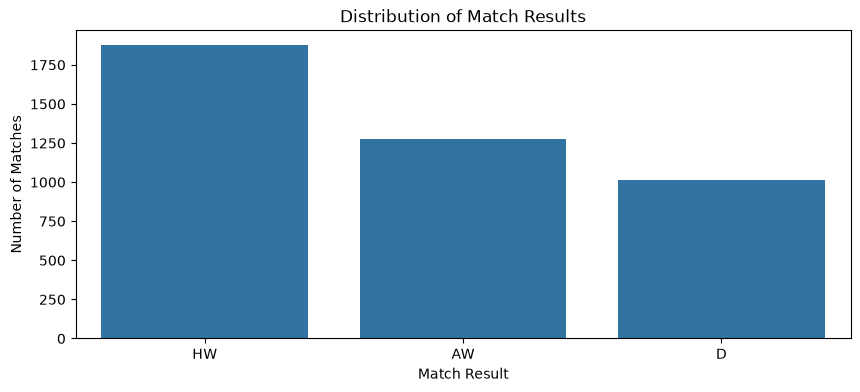

In [21]:
# EDA
#Match outcome distribution
result_counts=(clean_matches["MatchResult"].value_counts().reindex(["HW", "AW", "D"], fill_value=0))
result_percentage=(result_counts/result_counts.sum()*100).round(2)
print(result_counts)
print(result_percentage)
plt.figure(figsize=(10, 4))
sns.barplot(x=result_counts.index, y=result_counts.values)
plt.title("Distribution of Match Results")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")
plt.show()

Average Home Goals : 1.53
Average Away Goals:  1.21


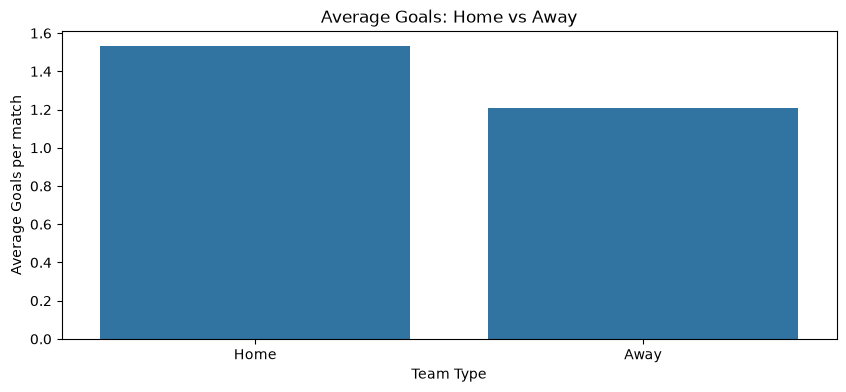

In [23]:
#Home advantage analysis
home_average=clean_matches["HomeGoals"].mean()
away_average= clean_matches["AwayGoals"].mean()
print("Average Home Goals :", round(home_average, 2))
print("Average Away Goals: ", round(away_average, 2))
goal_comparision=pd.DataFrame({
    "Team Type": ["Home", "Away"],
    "Average Goals": [home_average, away_average]
})
plt.figure(figsize=(10,4))
sns.barplot(data=goal_comparision, x="Team Type", y="Average Goals")
plt.title("Average Goals: Home vs Away")
plt.ylabel("Average Goals per match")
plt.show()

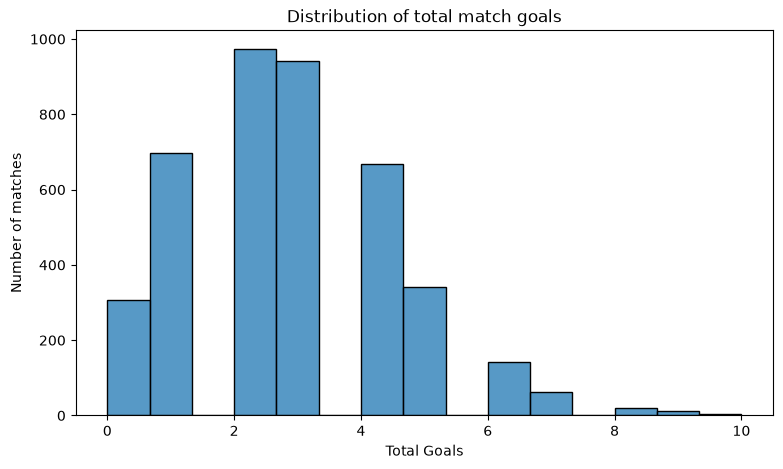

             Matches  Average_Goals  Home_Goals  Away_Goals
Source_File                                                
epl_2010_11      380           2.80        1.62        1.17
epl_2011_12      380           2.81        1.59        1.22
epl_2012_13      380           2.80        1.56        1.24
epl_2013_14      380           2.77        1.57        1.19
epl_2014_15      380           2.57        1.47        1.09
epl_2015_16      380           2.70        1.49        1.21
epl_2016_17      380           2.80        1.60        1.20
epl_2017_18      380           2.68        1.53        1.15
epl_2018_19      380           2.82        1.57        1.25
epl_2019_20      380           2.72        1.52        1.21
epl_2020_21      368           2.70        1.35        1.35


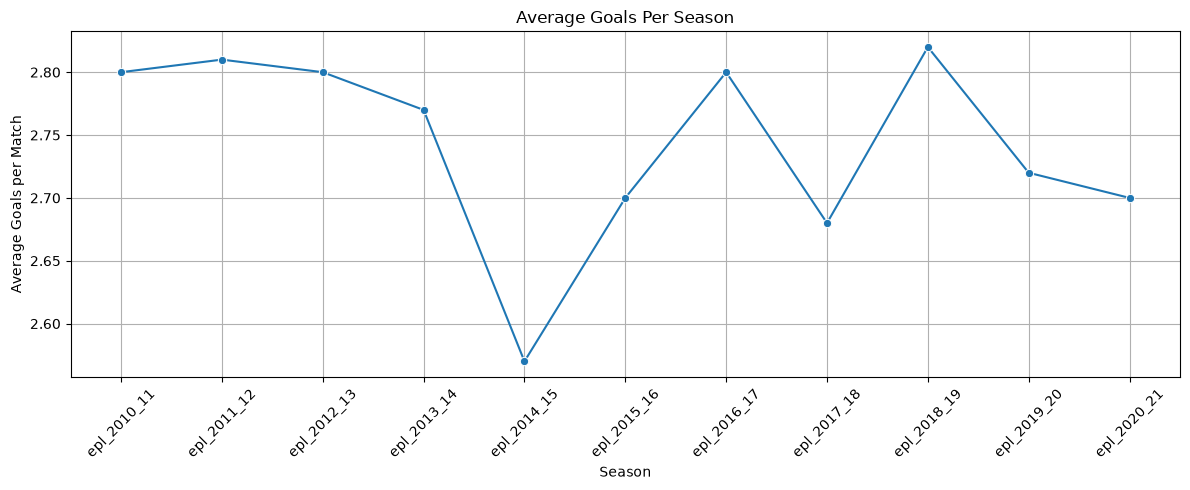

In [29]:
#Goal Distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=clean_matches, x="TotalGoals", bins=15)
plt.title("Distribution of total match goals")
plt.xlabel("Total Goals")
plt.ylabel("Number of matches")
plt.show()

#Seasonal
season_goals=(clean_matches.groupby("Source_File").agg(
    Matches=("TotalGoals", "count"),
    Average_Goals=("TotalGoals", "mean"),
    Home_Goals=("HomeGoals", "mean"),
    Away_Goals=("AwayGoals", "mean")
).round(2).sort_index())
print(season_goals)
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=season_goals,
    x=season_goals.index,
    y="Average_Goals",
    marker="o"
)
plt.title("Average Goals Per Season")
plt.xlabel("Season")
plt.ylabel("Average Goals per Match")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

HomeTeam
Manchester City FC      496
Liverpool FC            407
Arsenal FC              398
Chelsea FC              386
Manchester United FC    380
Name: HomeGoals, dtype: int64
AwayTeam
Manchester City FC      362
Liverpool FC            322
Tottenham Hotspur FC    306
Chelsea FC              305
Arsenal FC              304
Name: AwayGoals, dtype: int64


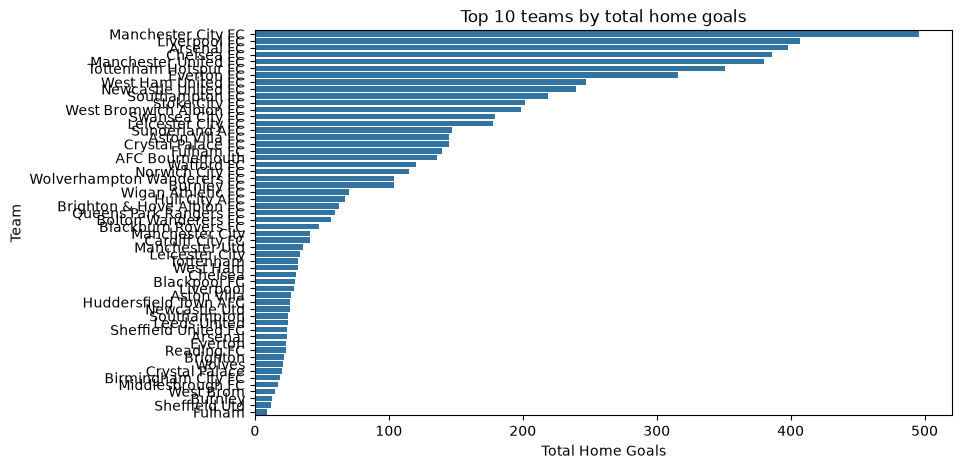

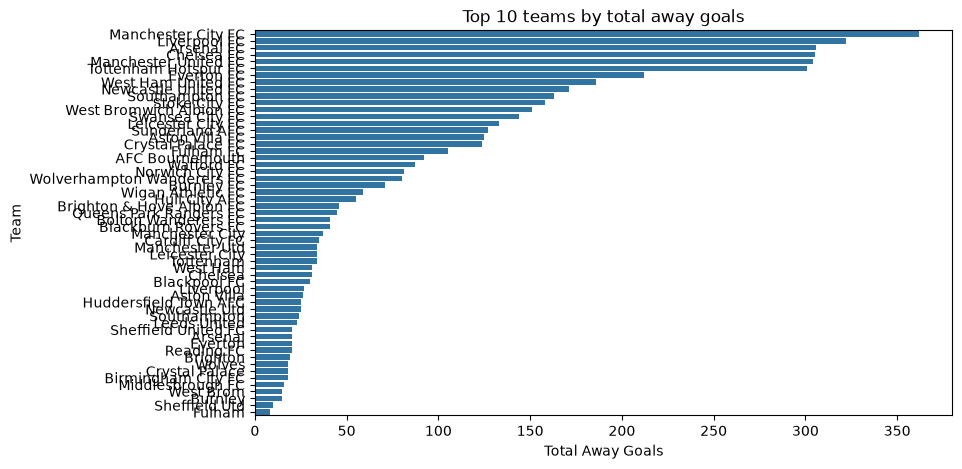

In [33]:
#Top scoring teams
home_team_goals=(clean_matches.groupby("HomeTeam")["HomeGoals"].sum().sort_values(ascending=False))
print(home_team_goals.head())
away_team_goals=(clean_matches.groupby("AwayTeam")["AwayGoals"].sum().sort_values(ascending=False))
print(away_team_goals.head())
plt.figure(figsize=(9, 5))
sns.barplot(x=home_team_goals.values, y=home_team_goals.index)
plt.title("Top 10 teams by total home goals")
plt.xlabel("Total Home Goals")
plt.ylabel("Team")
plt.show()
plt.figure(figsize=(9, 5))
sns.barplot(x=away_team_goals.values, y=home_team_goals.index)
plt.title("Top 10 teams by total away goals")
plt.xlabel("Total Away Goals")
plt.ylabel("Team")
plt.show()

In [34]:
os.makedirs("../data/processed", exist_ok=True)
clean_matches.to_csv("../data/processed/epl_matches_clean.csv")
print("Cleaned Dataset saved successfully.")

Cleaned Dataset saved successfully.


## OBESERVATION:
~~~
i. There is no invalid score records.
ii. MatchResult: Home Wins: 1876 matches, Away Wins: 1276 matches, Draw: 1016 matches
iii. Top Scoring Home Teams: 
Manchester City FC      496
Liverpool FC            407
Arsenal FC              398
Chelsea FC              386
Manchester United FC    380
iv: Top Scoring Away Teams:
Manchester City FC      362
Liverpool FC            322
Tottenham Hotspur FC    306
Chelsea FC              305
Arsenal FC              304
